# INFO 4360: Complex Data Analytics
## Course Project – Phase 2: Development

**Project:** Predicting Financial Product Categories from Consumer Complaint Narratives  
**Group Members:** Rebecca Quaye and Ketty Odero  
**Analysis Path:** Path A – Prediction/Classification


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
# Load the CFPB complaint dataset
df = pd.read_csv("../Data/cfpb_complaints_sample_2025-08_to_2026-07.csv")

df.head()

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2025-11-03,Mortgage,VA mortgage,Trouble during payment process,Payment process,"b""Summary\n\nShellpoint / XXXX have created a...",Company has responded to the consumer and the ...,"Shellpoint Partners, LLC",TN,37066,Servicemember,Web,2025-11-03,Closed with explanation,Yes,16983019
1,2026-04-27,Debt or credit management,Debt settlement,Didn't provide services promised,NaN,I am filing a complaint against Affirm regardi...,NaN,"Affirm Holdings, Inc",ME,049XX,Older American,Web,2026-04-27,Closed with explanation,Yes,21642170
2,2026-05-19,Debt or credit management,Debt settlement,Confusing or misleading advertising or marketing,NaN,"I received a credit card from "" Best Buy as "" ...",Company has responded to the consumer and the ...,"CITIBANK, N.A.",IL,XXXXX,Older American,Web,2026-07-08,Closed with explanation,Yes,22330665
3,2025-11-29,Debt collection,I do not know,False statements or representation,Attempted to collect wrong amount,I am writing in response to your communication...,NaN,V and H Portfolio,FL,33901,NaN,Web,2025-11-29,Closed with explanation,Yes,17887813
4,2026-02-09,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,I am formally disputing multiple inaccuracies ...,NaN,"EQUIFAX, INC.",CA,90044,NaN,Web,2026-02-09,Closed with non-monetary relief,Yes,19355999


### 1. Data Exploration

We first examine the size and structure of the CFPB complaint dataset.

In [3]:
# Check the dataset size and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

Number of rows: 5000
Number of columns: 16

Columns:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']


In [4]:
# Check missing values
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values

Tags                            4182
Company public response         3436
Sub-issue                       1398
State                             38
ZIP code                          10
Date received                      0
Product                            0
Sub-product                        0
Issue                              0
Consumer complaint narrative       0
Company                            0
Submitted via                      0
Date sent to company               0
Company response to consumer       0
Timely response?                   0
Complaint ID                       0
dtype: int64

In [5]:
# Summarize missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
missing_summary.sort_values("Missing Count", ascending=False)

,Missing Count,Missing Percent
Tags,4182,83.64
Company public response,3436,68.72
Sub-issue,1398,27.96
State,38,0.76
ZIP code,10,0.20


#### Missing Values

The primary variables for this project, **Consumer complaint narrative** and **Product**, have no missing values. This means all 5,000 complaints can be used for the planned text classification analysis. Missing values are concentrated in other fields such as Tags, Company public response, and Sub-issue, which are not the primary input or target variables for our model.

#### Product Distribution

Since **Product** is the target variable for our classification model, we examine how the 5,000 complaints are distributed across the financial product categories.

In [6]:
# Count complaints by product
product_counts = df["Product"].value_counts()

product_counts

Product
Debt or credit management                                  455
Debt collection                                            455
Credit reporting or other personal consumer reports        455
Credit card                                                455
Money transfer, virtual currency, or money service         455
Checking or savings account                                455
Mortgage                                                   454
Payday loan, title loan, personal loan, or advance loan    454
Vehicle loan or lease                                      454
Prepaid card                                               454
Student loan                                               454
Name: count, dtype: int64

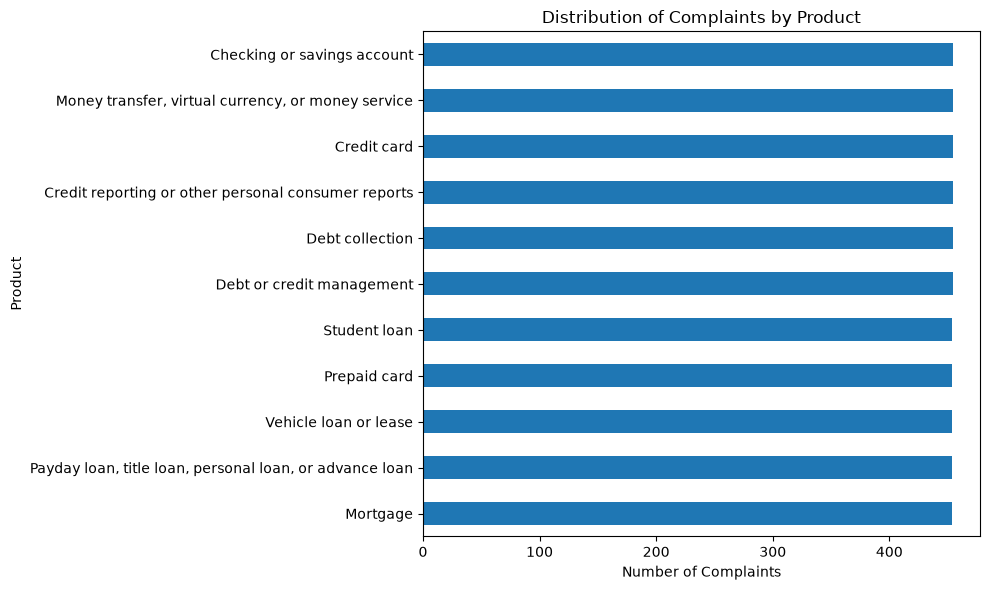

In [7]:
# Plot the product distribution
plt.figure(figsize=(10, 6))
product_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Complaints by Product")
plt.xlabel("Number of Complaints")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

#### Complaint Narrative Length

We examine the length of the consumer complaint narratives to understand how much the amount of text varies across complaints.

In [8]:
# Calculate narrative length in characters
df["narrative_length"] = df["Consumer complaint narrative"].str.len()

df["narrative_length"].describe()

count     5000.000000
mean      1346.446200
std       1543.571534
min         41.000000
25%        504.000000
50%        997.000000
75%       1691.250000
max      31435.000000
Name: narrative_length, dtype: float64

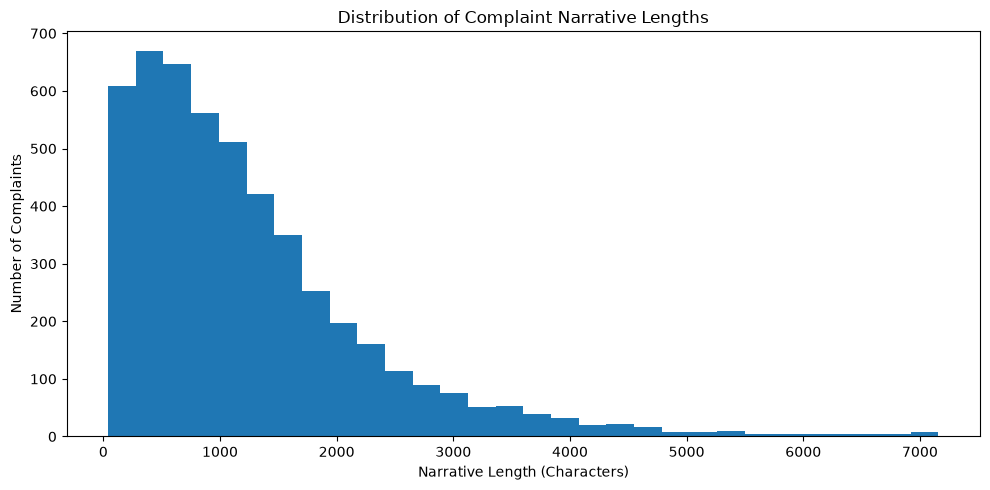

In [9]:
# Plot narrative lengths up to the 99th percentile
upper_limit = df["narrative_length"].quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(
    df.loc[df["narrative_length"] <= upper_limit, "narrative_length"],
    bins=30
)

plt.title("Distribution of Complaint Narrative Lengths")
plt.xlabel("Narrative Length (Characters)")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()

#### Narrative Length Interpretation

Complaint narrative lengths are right-skewed, with most complaints containing relatively short narratives and fewer complaints having very long narratives. The median narrative length is about 997 characters, while the mean is higher at about 1,346 characters. This difference reflects the presence of a smaller number of very long complaints.

For readability, the histogram displays narratives up to the 99th percentile. The full dataset, including longer narratives, is retained for the analysis. The variation in narrative length may be important when preprocessing the text and building the classification model.

In [10]:
# Display sample complaint narratives
sample_complaints = df[["Product", "Consumer complaint narrative"]].sample(
    n=5, random_state=42
)

for _, row in sample_complaints.iterrows():
    print("Product:", row["Product"])
    print("Narrative:", row["Consumer complaint narrative"][:500])
    print("-" * 80)

Product: Checking or savings account
Narrative: Complaint Against Synchrony Bank IRA CD Early Withdrawal Penalties I am submitting this complaint regarding early withdrawal penalties charged by Synchrony Bank in connection with withdrawals from XXXX of my IRA CDs. Before initiating the transaction on XX/XX/year>,, I called Synchrony Bank and asked a very specific question : whether I could withdraw any amount at any time for any reason. The representative informed me that I could, explaining that this was because I had reached the age at whic
--------------------------------------------------------------------------------
Product: Checking or savings account
Narrative: I called Huntington Bank customer service number ( XXXX ) on Monday on XXXX XXXX and spoke with a rep named XXXX or XXXX in an attempt to close the checking account. The balance on the account was XXXX and made sure to clear the balance to XXXX prior to closing the account. The rep said it will be closed but told me she 

#### Sample Narrative Observations

The sample complaints vary in length and writing style, but they contain language that provides clues about the financial product involved. For example, some narratives explicitly mention terms such as checking accounts, credit reports, money transfers, or vehicles. Other narratives may require more context to determine the appropriate product category.

This supports the use of text classification for categorizing unlabeled complaints, but it also highlights a potential concern: explicit product words may make some complaints easier to classify. We will examine this further in the modeling phase as part of our leakage and sanity checks.

### 2. Text Mining Basics

We begin by cleaning the complaint narratives for text analysis. The cleaned text will be used to examine common words and patterns across the complaints.

In [11]:
# Import text processing tools
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

#### Text Preprocessing

The complaint narratives are cleaned before the frequency analysis by converting text to lowercase, removing non-alphabetic characters and stopwords, and lemmatizing the remaining words.

In [12]:
# Set up text preprocessing
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Split text into individual words
    words = text.split()

    # Remove stopwords and redaction placeholders
    words = [
    word for word in words
    if word not in stop_words and not re.fullmatch(r"x+", word)
    ]

    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return " ".join(words)

In [13]:
# Apply the cleaning function
df["clean_narrative"] = df["Consumer complaint narrative"].apply(clean_text)

# Compare the original and cleaned text
df[["Consumer complaint narrative", "clean_narrative"]].head()

,Consumer complaint narrative,clean_narrative
0,"b""Summary\n\nShellpoint / XXXX have created a...",b summary n nshellpoint created pattern paymen...
1,I am filing a complaint against Affirm regardi...,filing complaint affirm regarding consumer loa...
2,"I received a credit card from "" Best Buy as "" ...",received credit card best buy paying card best...
3,I am writing in response to your communication...,writing response communication regarding above...
4,I am formally disputing multiple inaccuracies ...,formally disputing multiple inaccuracy equifax...


#### Word Frequency Analysis

We examine the most frequently occurring words across the complaint narratives to identify common themes and language in the dataset.

In [14]:
# Count the most common words

# Combine all cleaned narratives and split them into words
all_words = " ".join(df["clean_narrative"]).split()

# Count how often each word appears
word_counts = Counter(all_words)

# Get the 20 most common words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

# Display the results
top_words

,Word,Frequency
0,account,10486
1,credit,6570
2,payment,6564
3,loan,4458
4,year,3470
5,information,3461
6,reporting,3079
7,card,3073
8,bank,2995
9,time,2756


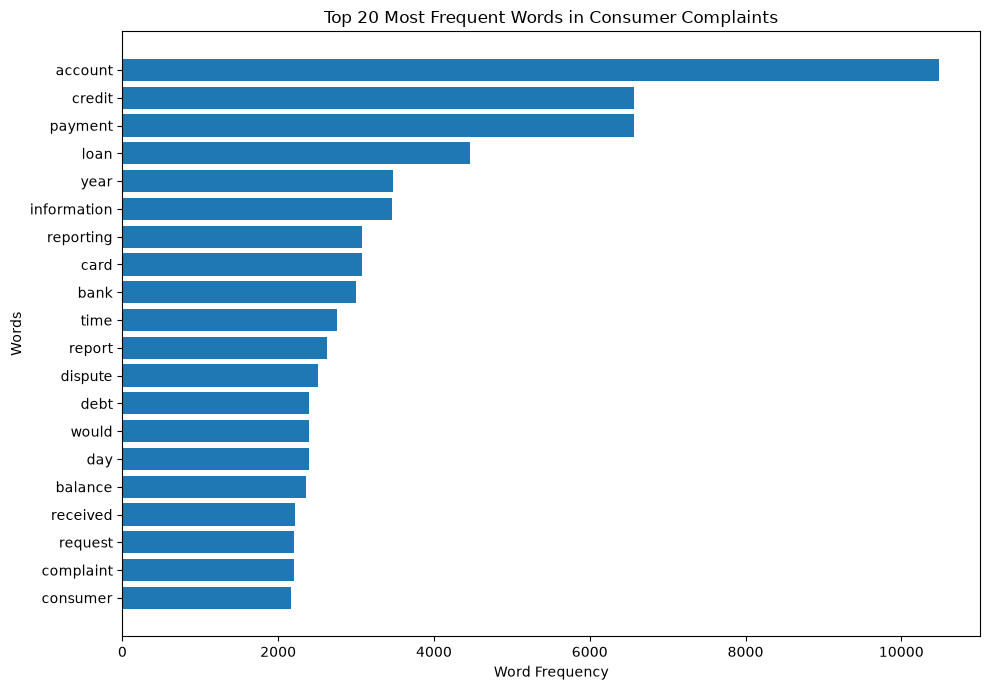

In [15]:
# Plot the 20 most frequent words
plt.figure(figsize=(10, 7))

plt.barh(top_words["Word"], top_words["Frequency"])

plt.title("Top 20 Most Frequent Words in Consumer Complaints")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

# Display the most frequent word at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

#### Word Frequency Interpretation

The word-frequency analysis shows that "account" is the most frequently occurring word (10,486), followed by "credit" (6,570), "payment" (6,564), and "loan" (4,458). Other common words include "bank," "card," "reporting," and "debt."

These results suggest that many complaints discuss financial accounts, payments, credit-related issues, and loans. The presence of product-related words also suggests that complaint narratives contain useful information for predicting financial product categories.

However, these frequencies represent the entire dataset. Examining common words within individual product categories may help us understand which terms distinguish one category from another.

#### Word Frequency by Product Category

We examine the most frequently occurring words within each financial product category to identify differences in the language consumers use when describing their complaints.

In [16]:
# Get the most common words for a product category
def get_top_words_by_product(product, n=10):
    
    # Select complaints belonging to the product
    product_text = df.loc[df["Product"] == product, "clean_narrative"]
    
    # Combine the narratives into individual words
    words = " ".join(product_text).split()
    
    # Count the words
    word_counts = Counter(words)
    
    # Return the most frequent words
    return pd.DataFrame(
        word_counts.most_common(n),
        columns=["Word", "Frequency"]
    )

In [17]:
# Display the 10 most common words in mortgage complaints
mortgage_words = get_top_words_by_product("Mortgage")

mortgage_words

,Word,Frequency
0,payment,1452
1,mortgage,1231
2,loan,1006
3,account,582
4,year,557
5,escrow,516
6,servicing,425
7,property,382
8,bank,380
9,received,364


#### Mortgage Complaint Word Frequency

Mortgage complaints frequently contain words such as "payment," "mortgage," "loan," "escrow," "servicing," and "property." These terms reflect common topics associated with mortgage lending and servicing.

The frequent appearance of "mortgage" suggests that some narratives explicitly identify their product category. This could make classification easier, so we plan to examine how model performance changes when explicit product-related terms are masked.

In [18]:
# Get the top 5 words for each product category
product_word_summary = []

for product in df["Product"].unique():
    top_words_product = get_top_words_by_product(product, n=5)

    product_word_summary.append({
        "Product": product,
        "Top 5 Words": ", ".join(top_words_product["Word"])
    })

# Display the summary
product_word_summary = pd.DataFrame(product_word_summary)

product_word_summary

,Product,Top 5 Words
0,Mortgage,"payment, mortgage, loan, account, year"
1,Debt or credit management,"account, credit, debt, payment, fee"
2,Debt collection,"account, debt, credit, reporting, collection"
3,Credit reporting or other personal consumer re...,"credit, account, reporting, information, report"
4,Credit card,"credit, account, card, payment, charge"
5,"Money transfer, virtual currency, or money ser...","account, transaction, fund, bank, app"
6,"Payday loan, title loan, personal loan, or adv...","loan, payment, account, credit, year"
7,Vehicle loan or lease,"payment, vehicle, account, loan, credit"
8,Prepaid card,"card, account, transaction, fund, dispute"
9,Checking or savings account,"account, bank, fund, transaction, year"


#### Sentiment Analysis Using VADER

We use VADER sentiment analysis to examine the emotional tone of consumer complaint narratives. VADER assigns sentiment scores based on the words and expressions in a text.

This analysis will help us understand the overall sentiment of complaints and compare sentiment across financial product categories.

In [19]:
# Import VADER
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download the VADER lexicon
nltk.download("vader_lexicon")

# Initialize the sentiment analyzer
sentiment_analyzer = SentimentIntensityAnalyzer()

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/rebeccaquaye/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [20]:
# Calculate sentiment scores for each complaint narrative
df["sentiment_scores"] = df["Consumer complaint narrative"].apply(
    lambda text: sentiment_analyzer.polarity_scores(text)
)

# Extract the compound sentiment score
df["compound_score"] = df["sentiment_scores"].apply(
    lambda scores: scores["compound"]
)

# Display the results
df[["Consumer complaint narrative", "compound_score"]].head()

,Consumer complaint narrative,compound_score
0,"b""Summary\n\nShellpoint / XXXX have created a...",0.9989
1,I am filing a complaint against Affirm regardi...,-0.9759
2,"I received a credit card from "" Best Buy as "" ...",0.9847
3,I am writing in response to your communication...,-0.9258
4,I am formally disputing multiple inaccuracies ...,-0.6705


In [21]:
# Classify sentiment based on compound scores
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# Apply the sentiment classification
df["sentiment_label"] = df["compound_score"].apply(classify_sentiment)

# Count complaints by sentiment
sentiment_counts = df["sentiment_label"].value_counts()

sentiment_counts

sentiment_label
Negative    2965
Positive    1851
Neutral      184
Name: count, dtype: int64

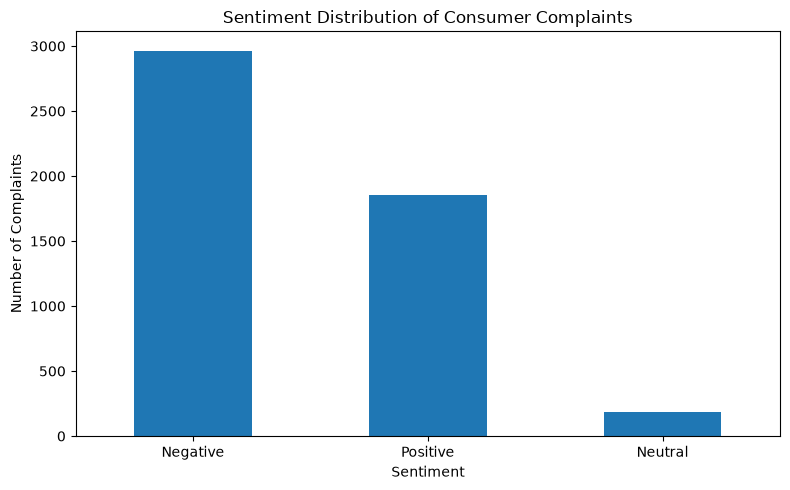

In [22]:
# Count complaints by sentiment
sentiment_counts = df["sentiment_label"].value_counts()

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

sentiment_counts.plot(kind="bar")

plt.title("Sentiment Distribution of Consumer Complaints")
plt.xlabel("Sentiment")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Sentiment Distribution Interpretation

VADER classified 59.30% of complaints as negative, 37.02% as positive, and 3.68% as neutral. Negative sentiment was the most common classification, which is consistent with the nature of consumer complaints.

However, the relatively high proportion of positive classifications raises questions about VADER's ability to capture the overall meaning of longer financial complaints. Some complaints may contain positive words while describing negative experiences.

These results should therefore be interpreted as baseline sentiment estimates rather than verified sentiment labels.

#### Sentiment Analysis by Product Category

We compare VADER sentiment classifications across the 11 financial product categories to examine differences in the emotional tone of consumer complaints.

In [23]:
# Count sentiment labels for each product
sentiment_by_product = pd.crosstab(
    df["Product"],
    df["sentiment_label"]
)

# Convert counts to percentages
sentiment_by_product_pct = (
    sentiment_by_product.div(sentiment_by_product.sum(axis=1), axis=0) * 100
).round(2)

# Display the results
sentiment_by_product_pct

sentiment_label,Negative,Neutral,Positive
Product,,,
Checking or savings account,70.11,3.96,25.93
Credit card,50.33,2.20,47.47
Credit reporting or other personal consumer reports,53.63,4.84,41.54
Debt collection,54.95,2.20,42.86
Debt or credit management,58.68,3.74,37.58
"Money transfer, virtual currency, or money service",73.41,3.74,22.86
Mortgage,61.01,3.08,35.90
"Payday loan, title loan, personal loan, or advance loan",55.29,5.51,39.21
Prepaid card,65.20,4.41,30.40


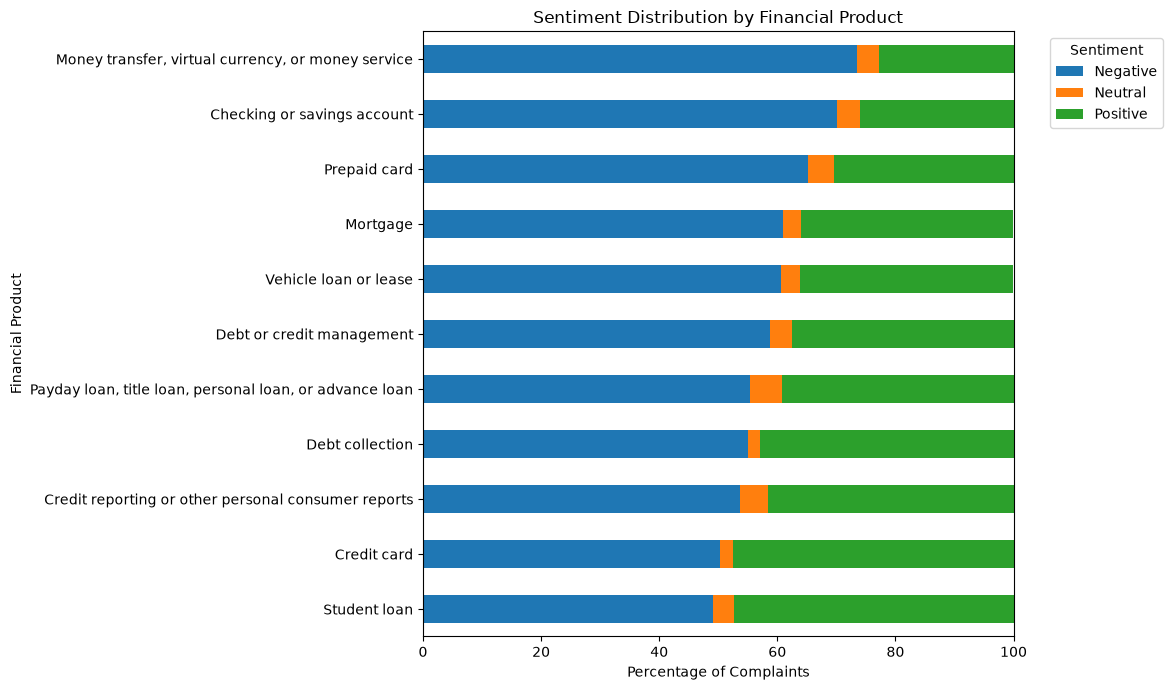

In [24]:
# Plot sentiment percentages by product
sentiment_by_product_pct = sentiment_by_product_pct.sort_values(
    "Negative", ascending=True
)

sentiment_by_product_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Sentiment Distribution by Financial Product")
plt.xlabel("Percentage of Complaints")
plt.ylabel("Financial Product")
plt.legend(title="Sentiment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

#### Sentiment by Product Interpretation

VADER sentiment classifications vary across financial product categories. Money transfer complaints had the highest percentage of negative sentiment (73.41%), followed by checking or savings accounts (70.11%) and prepaid cards (65.20%).

Student loan complaints had the lowest percentage of negative sentiment (49.12%), while credit card complaints had 50.33%. Both categories also had relatively high percentages of positive classifications.

These differences suggest that the language used in complaints varies across financial products. However, VADER may not always capture the overall meaning of complex financial complaints, so these results should not be interpreted as direct measures of customer satisfaction.

## 3. Phase 3 Modeling Plan

### Analysis Approach

Our project follows Path A: Prediction/Classification. The goal is to predict the financial product category associated with a consumer complaint using the complaint narrative.

The **Consumer complaint narrative** will serve as the input variable (X), while **Product** will be the target variable (Y).

We will use the CFPB dataset to train and evaluate a multiclass classification model that predicts one of 11 financial product categories.

Although CFPB complaints already have product labels, our proposed application is for financial institutions receiving complaints through channels such as emails, chat messages, or phone transcripts, where the product category may not already be identified.

The model could help automatically categorize these incoming complaints and route them to the appropriate teams.

## Model Development and Evaluation Plan

We plan to use TF-IDF vectorization to convert the complaint narratives into numerical features that machine learning models can process. We will consider both individual words (unigrams) and two-word combinations (bigrams).

The dataset will be divided into 70% training data and 30% testing data using stratified sampling to maintain the distribution of the 11 product categories.

We will begin with Logistic Regression as our baseline classification model and compare its performance with Multinomial Naive Bayes and Linear Support Vector Machine (SVM).

Model performance will be evaluated using:

- **Accuracy:** The overall percentage of correctly classified complaints.
- **Macro F1-score:** The average F1-score across all 11 product categories, giving each category equal importance.
- **Precision and Recall:** To examine how well the model performs for individual product categories.
- **Confusion Matrix:** To identify which financial products are frequently confused with one another.

We also plan to conduct a sanity check by masking explicit product-related terms such as "mortgage," "credit card," and "student loan" in the complaint narratives. We will compare model performance before and after masking these terms to investigate whether the model relies heavily on obvious product names rather than broader contextual information.

This experiment will help us better understand how the model might perform when classifying incoming complaints that do not explicitly mention their financial product.

## Claude API Integration Plan

We plan to use Claude API to support our analysis in Phase 3, particularly for understanding classification errors and comparing predictions.

After training our machine learning models, we will select a small sample of complaint narratives and ask Claude to predict their financial product categories using the same 11 categories in our dataset.

We will compare Claude's predictions with the actual product labels and the predictions from our machine learning models. This will help us identify cases where the models agree or disagree.

We also plan to use Claude for error analysis by asking it to examine selected misclassified complaints and explain which words or contextual clues may have contributed to the confusion.

An example prompt will be:

"Read the following consumer financial complaint and identify the most appropriate financial product category from the 11 categories provided. Return only the selected category and a brief explanation based on the complaint narrative."

We will consider several limitations when using Claude:

- **Privacy:** Complaint narratives will be reviewed for sensitive information before being sent to the API.
- **API cost:** We will use a small sample to manage token usage and costs.
- **Consistency:** We will use a standardized prompt and fixed model settings where possible.
- **Validity:** Claude's predictions and explanations will be treated as exploratory results rather than automatically correct answers.
- **Scalability:** Using Claude for thousands of complaints may be more expensive and slower than traditional classification models.

Claude will serve as a supporting tool rather than replacing our primary machine learning classification models.

### 4. Phase 2 Progress Update

#### Work Completed

During Phase 2, we explored a sample of 5,000 CFPB consumer complaints covering 11 financial product categories.

We examined the dataset structure, missing values, product distribution, and complaint narrative lengths. We also cleaned the narratives and performed word-frequency analysis to identify common terms across the dataset and within individual product categories.

Finally, we used VADER to conduct baseline sentiment analysis and compare sentiment classifications across financial products.

#### Preliminary Findings

- The dataset is nearly balanced across the 11 product categories, with 454 or 455 complaints per category.
- The complaint narratives and product labels have no missing values.
- Words such as "account," "credit," "payment," and "loan" appear frequently across the complaints.
- Certain categories contain more specific terms, such as "mortgage," "vehicle," and "mohela," which may help distinguish financial products.
- VADER classified 59.30% of complaints as negative, 37.02% as positive, and 3.68% as neutral. However, these results may not fully reflect the context of longer financial complaints.

#### Next Steps

In Phase 3, we plan to develop and compare multiclass classification models using TF-IDF features and Logistic Regression, Multinomial Naive Bayes, and Linear SVM.

We will evaluate model performance using macro F1-score, accuracy, per-class precision and recall, and a confusion matrix.

We will also investigate how masking explicit product-related words affects classification performance and use Claude API on a small sample of complaints for prediction comparison and error analysis.